# SWE reconstruction: old port vs original-faithful port

Runs the SWE UDFs locally on the same synthetic season.

| Run | UDF | Band 2 | Shortwave |
|---|---|---|---|
| **old (pipeline wiring)** | old | relative humidity (%), as `snow_water_equivalent.py` used to merge it | MJ/m²/day (`/1e6`) |
| **old + precip** | old | AGERA5 precipitation (mm/day) | MJ/m²/day |
| **new** | `src/.../snow_water_equivalent_udf.py` | precipitation (mm/day) | W/m² |

The new UDF follows the original:

- three-state status with the 2 °C, 5 mm and basin SCA increase rules;
- melt counts only on melting days;
- SWE carries over on neutral days;
- Pomeroy albedo with a 2 °C threshold and a 60 mm cap;
- TF = 0.24 and SRF = 0.15;
- output rounded to whole mm.

The reference curve comes from a simple degree-day model that also generates the SCA. It is only a sanity reference, not the truth for this algorithm.

In [8]:
import importlib.util
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from openeo.udf import UdfData, XarrayDataCube
from openeo.udf.run_code import run_udf_code

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
OLD_UDF = ROOT / 'scripts/old_udfs/snow_water_equivalent_udf.py'
NEW_UDF = ROOT / 'src/openeo_mountains_snow/snow_water_equivalent/udfs/snow_water_equivalent_udf.py'


def run_udf(path, cube, context=None):
    data = UdfData(datacube_list=[XarrayDataCube(cube)], user_context=context or {})
    return run_udf_code(code=Path(path).read_text(), data=data).get_datacube_list()[0].get_array()


spec = importlib.util.spec_from_file_location('new_swe', NEW_UDF)
new_swe = importlib.util.module_from_spec(spec)
spec.loader.exec_module(new_swe)

## Synthetic season

- **Grid:** 8x8 pixels with elevation from 1000 to 3000 m.
- **Season:** 1 Oct to 31 Aug, long enough for melt-out at 3000 m. The reconstruction needs a melt-out to redistribute melt.
- **Temperature:** a seasonal curve plus noise, with a lapse rate of -6.5 °C/km.
- **Precipitation:** random events.
- **Shortwave and RH:** seasonal shortwave, noisy RH.
- **SCA:** from the reference degree-day model, gap-free as the SCA reconstruction delivers it.
- **Cloudy run:** the extra run "new, 5% cloudy days" shows the original behaviour that a cloud (205) day sets SWE to NaN and the NaN carries forward until snow-free.


In [9]:
rng = np.random.default_rng(1)
time = pd.date_range('2022-10-01', '2023-08-31')  # long enough for melt-out at 3000 m
NT, NY, NX = len(time), 8, 8
s = np.arange(NT)
elev = np.linspace(1000, 3000, NX)[None, :].repeat(NY, 0)

ta_1000 = 9 - 14 * np.sin(np.pi * np.clip(s, 0, 200) / 200) + np.clip(s - 200, 0, None) * 0.12 + rng.normal(0, 3, NT)
ta = ta_1000[:, None, None] - 6.5 * (elev[None] - 1000) / 1000
pr = np.where(rng.random(NT) < 0.3, rng.gamma(0.8, 12, NT), 0.0)[:, None, None] * (1 + (elev[None] - 1000) / 4000)
sw = (90 + 230 * np.sin(np.pi * (s + 80) / 365) ** 2 + rng.normal(0, 30, NT))[:, None, None] * np.ones((1, NY, NX))
rh = np.clip(70 + rng.normal(0, 15, (NT, 1, 1)), 10, 100) * np.ones((1, NY, NX))

ref = np.zeros((NT, NY, NX))
for t in range(1, NT):
    acc = np.where(ta[t] < 1, pr[t], 0)
    melt = 3.0 * np.clip(ta[t], 0, None)
    ref[t] = np.clip(ref[t - 1] + acc - melt, 0, None)
sca = np.where(ref > 1, 100.0, 0.0)  # gap-free, as delivered by the SCA reconstruction
sca[0] = 0
sca_cloudy = sca.copy()
sca_cloudy[rng.random(NT) < 0.05] = 205  # leftover clouds after gap filling


def make(bands):
    return xr.DataArray(np.stack(bands, axis=1).astype(np.float32), dims=('t', 'bands', 'y', 'x'),
                        coords={'t': time, 'bands': ['sca', 'ta', 'b2', 'sw'],
                                'y': 5_150_000 - 20 * np.arange(NY), 'x': 650_000 + 20 * np.arange(NX)})


sw_mj = sw * 86400 / 1e6
runs = {
    'old (pipeline wiring)': run_udf(OLD_UDF, make([sca, ta, rh, sw_mj])),
    'old + precip': run_udf(OLD_UDF, make([sca, ta, pr, sw_mj])),
    'new': run_udf(NEW_UDF, make([sca, ta, pr, sw])),
    'new, 5% cloudy days': run_udf(NEW_UDF, make([sca_cloudy, ta, pr, sw])),
}
swe = {k: v.isel(bands=0).values for k, v in runs.items()}


## SWE time series at three elevations

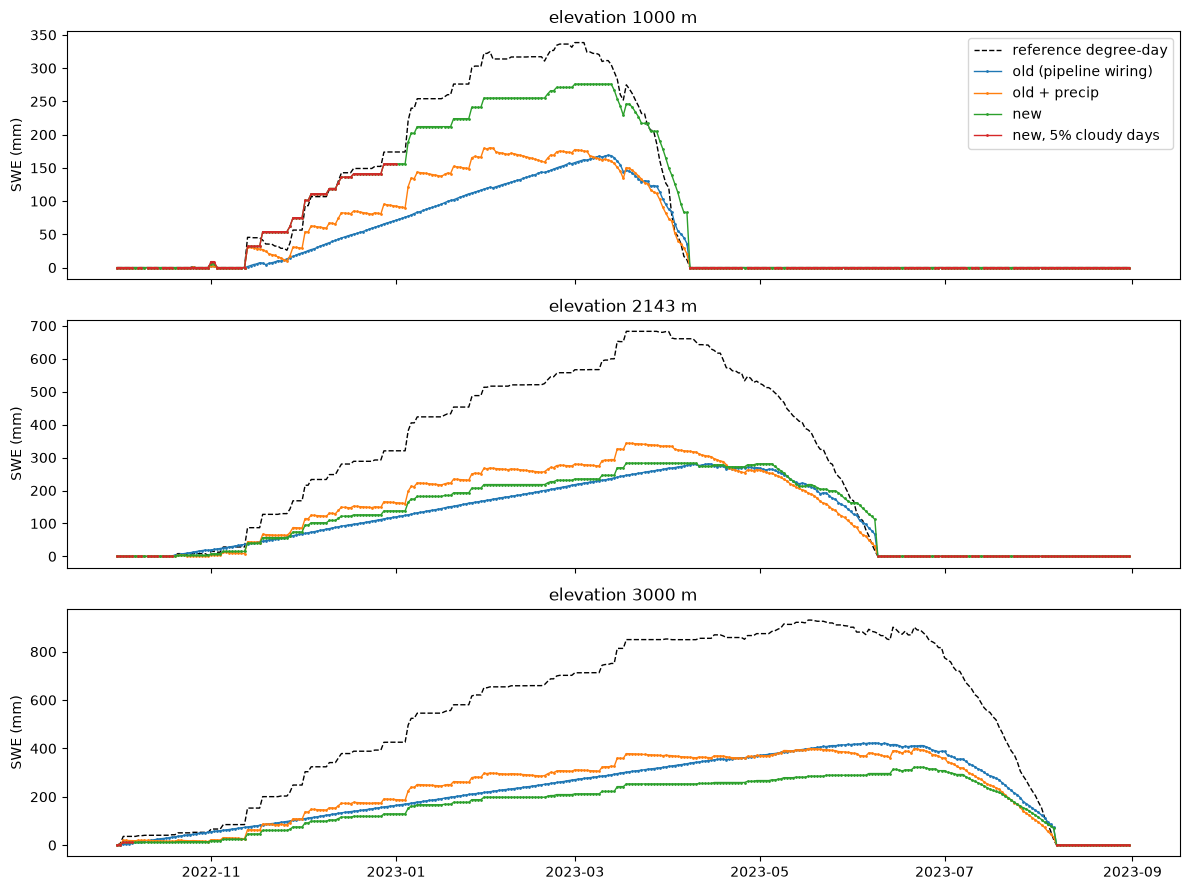

In [10]:
cols = [0, NX // 2, NX - 1]
fig, axes = plt.subplots(len(cols), 1, figsize=(12, 9), sharex=True)
for ax, c in zip(axes, cols):
    ax.plot(time, ref[:, 0, c], 'k--', lw=1, label='reference degree-day')
    for name, a in swe.items():
        ax.plot(time, a[:, 0, c], marker='.', ms=2, lw=1, label=name)
    ax.set_ylabel('SWE (mm)')
    ax.set_title(f'elevation {elev[0, c]:.0f} m')
axes[0].legend()
plt.tight_layout()

## Drivers in the new UDF (lowest pixel)

This shows status (1 = accumulation, 0 = neutral, -1 = melting), daily melt and albedo-driven melt, recomputed with the functions of the new UDF.

days per status (new, middle pixel): {np.int8(-1): np.int64(129), np.int8(0): np.int64(172), np.int8(1): np.int64(34)}


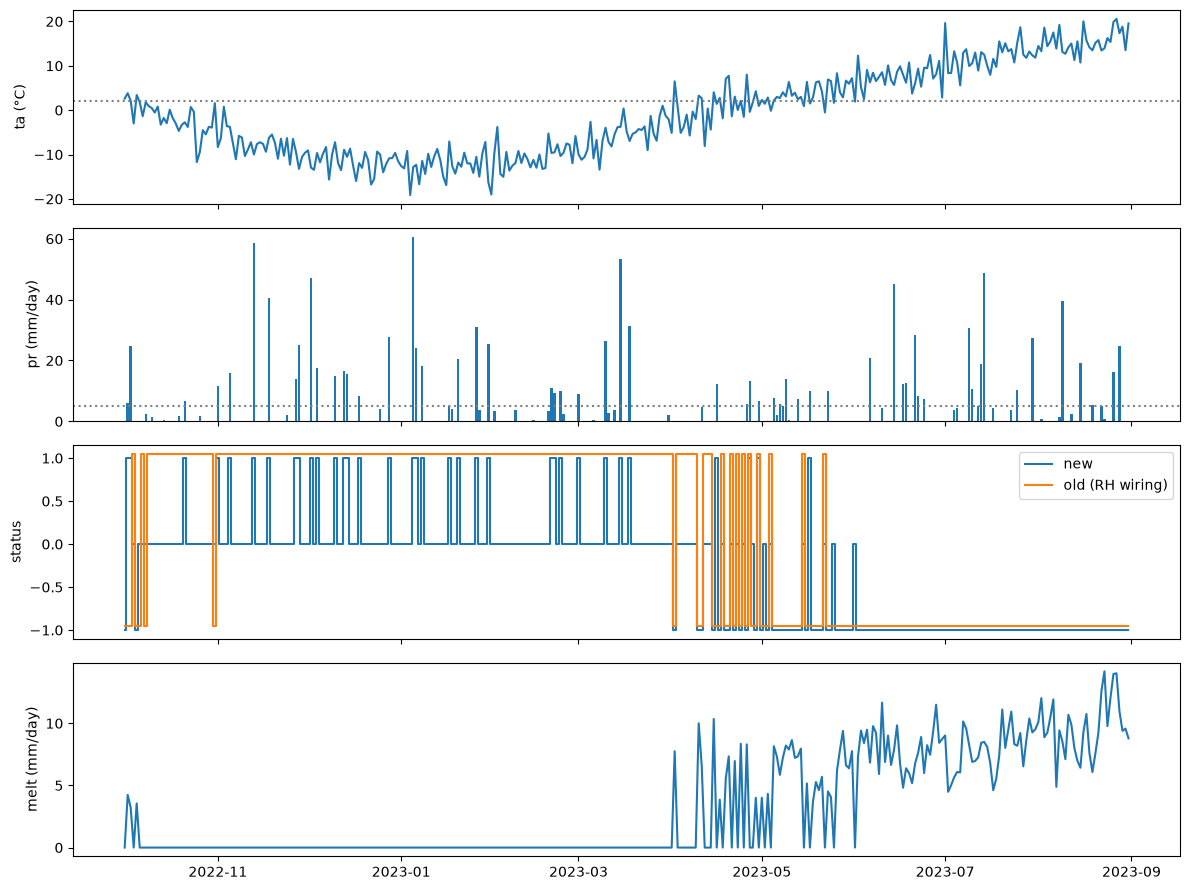

In [11]:
p = new_swe.DEFAULTS
status, delta = new_swe.get_status_and_delta(sca, ta, pr, p)
melt = new_swe.get_melt_pomeroy(sca, ta, pr, sw, status, p)
old_status = np.where((ta < 1) & (rh > 1), 1, -1)  # old rule, with RH as wired in the pipeline
c = NX // 2
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
axes[0].plot(time, ta[:, 0, c]); axes[0].axhline(2, color='grey', ls=':'); axes[0].set_ylabel('ta (°C)')
axes[1].bar(time, pr[:, 0, c]); axes[1].axhline(5, color='grey', ls=':'); axes[1].set_ylabel('pr (mm/day)')
axes[2].step(time, status[:, 0, c], where='mid', label='new'); axes[2].step(time, old_status[:, 0, c] + 0.05, where='mid', label='old (RH wiring)')
axes[2].set_ylabel('status'); axes[2].legend()
axes[3].plot(time, melt[:, 0, c]); axes[3].set_ylabel('melt (mm/day)')
plt.tight_layout()
print('days per status (new, middle pixel):', dict(zip(*np.unique(status[:, 0, c], return_counts=True))))

## Peak SWE per elevation and summary

,peak SWE mean (mm),seasonal mean SWE (mm),NaN share,non-integer values
old (pipeline wiring),282.447906,114.421837,0.0,True
old + precip,314.876282,132.098801,0.0,True
new,303.5,123.78582,0.0,False
"new, 5% cloudy days",80.625,19.647503,0.604104,False


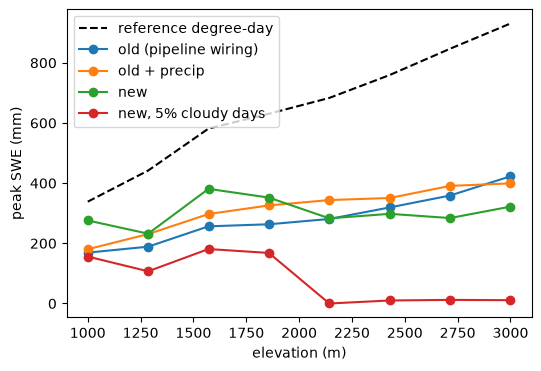

In [12]:
plt.figure(figsize=(6, 4))
plt.plot(elev[0], ref.max(0)[0], 'k--', label='reference degree-day')
for name, a in swe.items():
    plt.plot(elev[0], np.nanmax(a, axis=0)[0], marker='o', label=name)
plt.xlabel('elevation (m)'); plt.ylabel('peak SWE (mm)'); plt.legend()

summary = pd.DataFrame({name: {'peak SWE mean (mm)': np.nanmax(a, axis=0).mean(),
                               'seasonal mean SWE (mm)': np.nanmean(a),
                               'NaN share': np.isnan(a).mean(),
                               'non-integer values': bool(np.any(np.nan_to_num(a) % 1))}
                        for name, a in swe.items()}).T
summary